# Сегментація клієнтів торгового центру методом K-means

**Курс:** Fundamentals of Data Mining 2026 · **Модуль:** Basic Part (Laboratory Work)
**Автор:** Богдан Герасименко

Датасет: Mall Customer Segmentation Data (`data/Mall_Customers.csv`).

План: завантаження → перевірка якості та викидів → EDA (у т.ч. тест Манна–Уітні та статистика Гопкінса) →
власна реалізація K-means і звірка зі scikit-learn → вибір набору ознак і k за чотирма критеріями →
порівняння ініціалізацій → фінальна модель і профілі сегментів → оцінка якості (silhouette, DB, CH, bootstrap-стабільність,
альтернативні алгоритми) → візуалізація (області кластерів, PCA-біплот, профілі).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

SEED = 42
FIG = Path("figures")
RES = Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
PALETTE = ["#2a9d8f", "#e76f51", "#264653", "#e9c46a", "#8d5fd3", "#f4a261"]
GENDER_COLORS = {"Female": "#d1495b", "Male": "#00798c"}
summary = {}


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 1. Завантаження даних

In [2]:
raw = pd.read_csv("data/Mall_Customers.csv")
df = raw.rename(columns={"CustomerID": "id", "Gender": "gender", "Age": "age",
                         "Annual Income (k$)": "income", "Spending Score (1-100)": "spending"})
print(df.shape)
df.info()
df.head()

(200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        200 non-null    int64
 1   gender    200 non-null    str  
 2   age       200 non-null    int64
 3   income    200 non-null    int64
 4   spending  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


,id,gender,age,income,spending
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
NUM = ["age", "income", "spending"]
desc = df[NUM].describe().T
desc["skew"] = df[NUM].skew()
desc["kurtosis"] = df[NUM].kurt()
summary["describe"] = desc.round(3).to_dict("index")
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,200.0,38.85,13.97,18.0,28.75,36.0,49.0,70.0,0.49,-0.67
income,200.0,60.56,26.26,15.0,41.50,61.5,78.0,137.0,0.32,-0.10
spending,200.0,50.20,25.82,1.0,34.75,50.0,73.0,99.0,-0.05,-0.83


## 2. Попередня обробка

### 2.1 Пропуски, дублікати, некоректні значення

In [4]:
checks = {
    "missing": int(df.isna().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_ids": int(df["id"].duplicated().sum()),
    "duplicates_without_id": int(df.drop(columns="id").duplicated().sum()),
    "bad_gender": int((~df["gender"].isin(["Male", "Female"])).sum()),
    "bad_age": int((~df["age"].between(18, 100)).sum()),
    "bad_income": int((df["income"] <= 0).sum()),
    "bad_spending": int((~df["spending"].between(1, 100)).sum()),
}
summary["checks"] = checks
checks

{'missing': 0,
 'duplicate_rows': 0,
 'duplicate_ids': 0,
 'duplicates_without_id': 0,
 'bad_gender': 0,
 'bad_age': 0,
 'bad_income': 0,
 'bad_spending': 0}

### 2.2 Викиди: правило IQR та z-score

In [5]:
rows = []
for c in NUM:
    q1, q3 = df[c].quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    z = np.abs(stats.zscore(df[c]))
    rows.append({"feature": c, "q1": q1, "q3": q3, "low": low, "high": high,
                 "iqr_outliers": int(((df[c] < low) | (df[c] > high)).sum()),
                 "z_max": float(z.max()), "z_outliers": int((z > 3).sum())})
outliers = pd.DataFrame(rows)
summary["outliers"] = outliers.round(3).to_dict("records")
income_high = outliers.set_index("feature").loc["income", "high"]
summary["income_outlier_rows"] = df[df["income"] > income_high][["id", "gender", "age", "income", "spending"]].to_dict("records")
display(outliers.round(2))
df[df["income"] > income_high]

,feature,q1,q3,low,high,iqr_outliers,z_max,z_outliers
0,age,28.75,49.0,-1.62,79.38,0,2.24,0
1,income,41.50,78.0,-13.25,132.75,2,2.92,0
2,spending,34.75,73.0,-22.62,130.38,0,1.91,0


,id,gender,age,income,spending
198,199,Male,32,137,18
199,200,Male,30,137,83


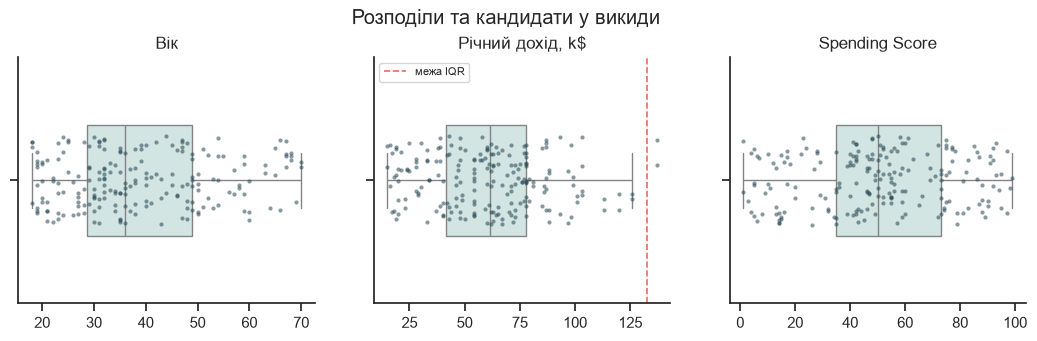

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
titles = {"age": "Вік", "income": "Річний дохід, k$", "spending": "Spending Score"}
for ax, c in zip(axes, NUM):
    sns.boxplot(x=df[c], ax=ax, color="#cfe8e4", width=0.45, fliersize=0)
    sns.stripplot(x=df[c], ax=ax, color="#264653", size=3, alpha=0.55, jitter=0.18)
    lim = outliers.set_index("feature").loc[c]
    if lim["high"] < df[c].max():
        ax.axvline(lim["high"], color="#e76f51", ls="--", lw=1.2, label="межа IQR")
        ax.legend(loc="upper left", fontsize=8)
    ax.set_title(titles[c])
    ax.set_xlabel("")
fig.suptitle("Розподіли та кандидати у викиди", y=1.03)
save(fig, "01_outliers")

Обидва «викиди» за IQR — клієнти з доходом 137 k$ (z ≈ 2,9, тобто за правилом |z| > 3 викидів немає).
Значення правдоподібні, тому записи залишено; вплив на K-means обмежений, бо після стандартизації вони не відірвані від решти точок.

### 2.3 Кодування, набори ознак і масштабування

In [7]:
df["is_female"] = (df["gender"] == "Female").astype(int)
FEATURE_SETS = {"F2": ["income", "spending"], "F3": ["age", "income", "spending"]}
scalers = {name: StandardScaler().fit(df[cols]) for name, cols in FEATURE_SETS.items()}
X = {name: scalers[name].transform(df[cols]) for name, cols in FEATURE_SETS.items()}
pd.DataFrame(X["F3"], columns=FEATURE_SETS["F3"]).describe().round(3)

,age,income,spending
count,200.000,200.000,200.000
mean,-0.000,-0.000,-0.000
std,1.003,1.003,1.003
min,-1.496,-1.739,-1.910
25%,-0.725,-0.728,-0.600
50%,-0.205,0.036,-0.008
75%,0.728,0.666,0.885
max,2.236,2.918,1.894


## 3. Розвідувальний аналіз (EDA)

### 3.1 Відмінності між чоловіками та жінками (тест Манна–Уітні)

In [8]:
rows = []
for c in NUM:
    f = df.loc[df["gender"] == "Female", c]
    m = df.loc[df["gender"] == "Male", c]
    u, p = stats.mannwhitneyu(f, m, alternative="two-sided")
    rows.append({"feature": c, "female_mean": f.mean(), "male_mean": m.mean(),
                 "female_median": f.median(), "male_median": m.median(), "U": u, "p_value": p})
gender_tests = pd.DataFrame(rows)
summary["gender_counts"] = df["gender"].value_counts().to_dict()
summary["gender_tests"] = gender_tests.round(4).to_dict("records")
gender_tests.round(3)

,feature,female_mean,male_mean,female_median,male_median,U,p_value
0,age,38.098,39.807,35.0,37.0,4728.5,0.624
1,income,59.250,62.227,60.0,62.5,4596.0,0.414
2,spending,51.527,48.511,50.0,50.0,5158.5,0.571


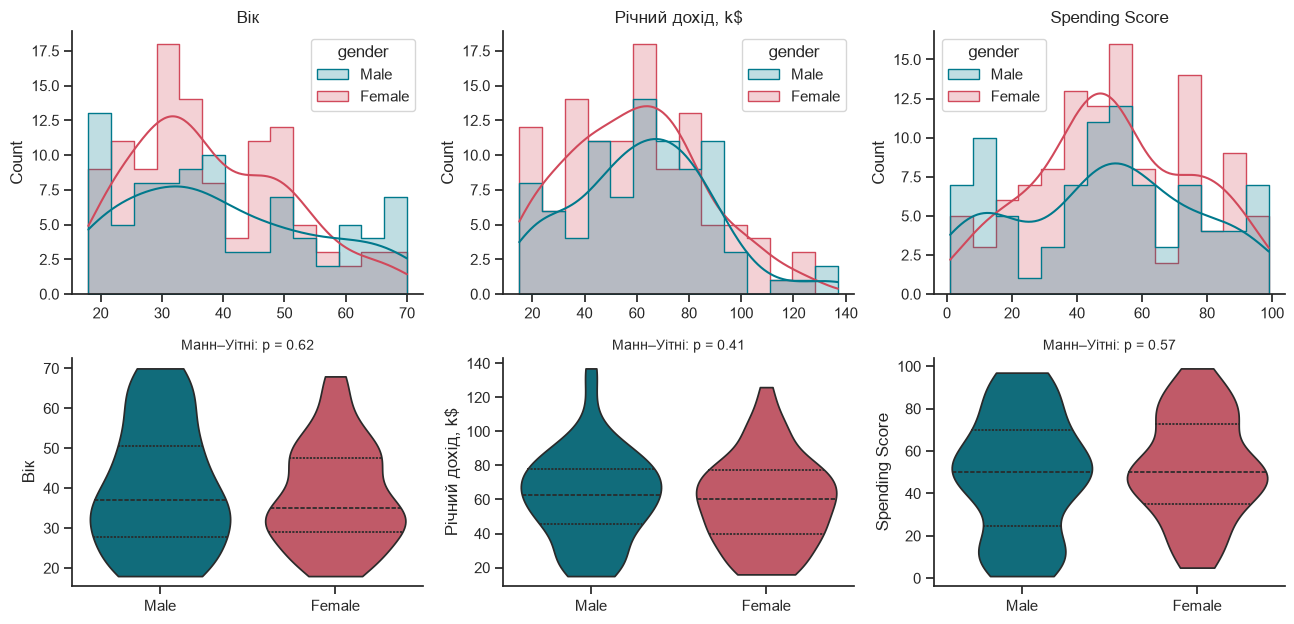

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), gridspec_kw={"height_ratios": [1.15, 1]})
for i, c in enumerate(NUM):
    sns.histplot(df, x=c, hue="gender", palette=GENDER_COLORS, bins=14, kde=True,
                 element="step", stat="count", common_norm=False, ax=axes[0, i], alpha=0.25)
    axes[0, i].set_title(titles[c])
    axes[0, i].set_xlabel("")
    sns.violinplot(df, x="gender", y=c, hue="gender", palette=GENDER_COLORS, inner="quart",
                   ax=axes[1, i], legend=False, cut=0)
    p = gender_tests.set_index("feature").loc[c, "p_value"]
    axes[1, i].set_title(f"Манн–Уітні: p = {p:.2f}", fontsize=10)
    axes[1, i].set_xlabel("")
    axes[1, i].set_ylabel(titles[c])
fig.tight_layout()
save(fig, "02_distributions")

### 3.2 Вікові групи

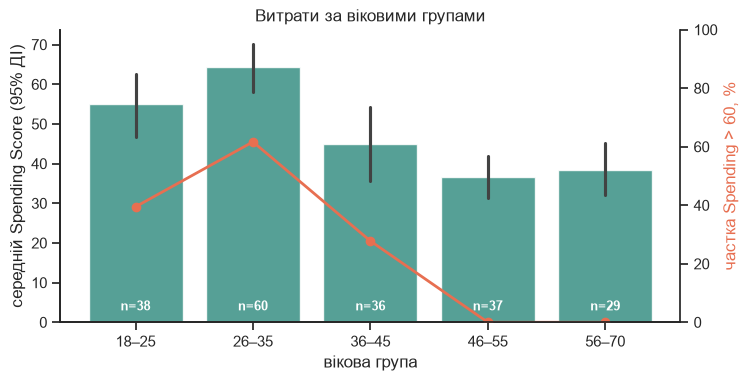

,n,income,spending,high_spenders
age_group,,,,
18–25,38,45.68,54.95,0.39
26–35,60,68.15,64.45,0.62
36–45,36,72.06,44.83,0.28
46–55,37,57.73,36.70,0.00
56–70,29,53.69,38.38,0.00


In [10]:
df["age_group"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 55, 70],
                         labels=["18–25", "26–35", "36–45", "46–55", "56–70"])
age_tab = df.groupby("age_group", observed=True).agg(
    n=("id", "size"), income=("income", "mean"), spending=("spending", "mean"),
    high_spenders=("spending", lambda s: (s > 60).mean()))
summary["age_groups"] = age_tab.round(3).reset_index().astype({"age_group": str}).to_dict("records")

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(df, x="age_group", y="spending", color="#2a9d8f", errorbar=("ci", 95), ax=ax, alpha=0.85)
ax2 = ax.twinx()
ax2.plot(range(len(age_tab)), age_tab["high_spenders"] * 100, "o-", color="#e76f51", lw=2)
ax2.set_ylabel("частка Spending > 60, %", color="#e76f51")
ax2.set_ylim(0, 100)
ax2.spines["right"].set_visible(True)
for i, n in enumerate(age_tab["n"]):
    ax.text(i, 3, f"n={n}", ha="center", color="white", fontsize=9, fontweight="bold")
ax.set_xlabel("вікова група")
ax.set_ylabel("середній Spending Score (95% ДІ)")
ax.set_title("Витрати за віковими групами")
save(fig, "03_age_groups")
age_tab.round(2)

### 3.3 Кореляції та попарні залежності

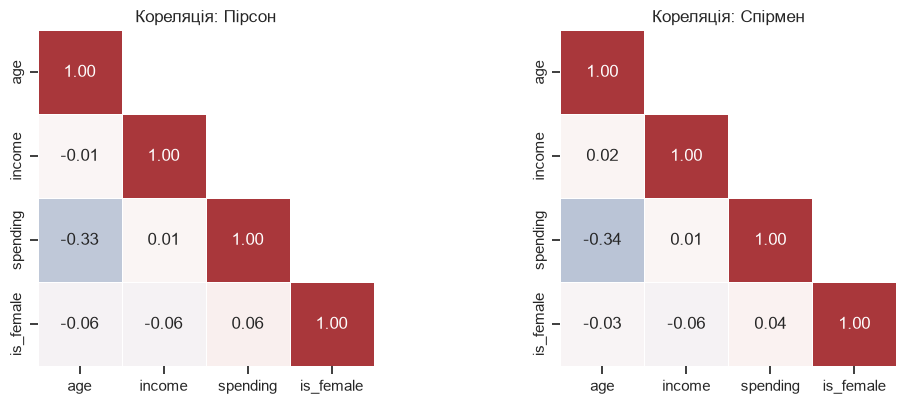

In [11]:
corr_cols = ["age", "income", "spending", "is_female"]
pearson = df[corr_cols].corr(method="pearson")
spearman = df[corr_cols].corr(method="spearman")
summary["corr_pearson"] = pearson.round(3).to_dict()
summary["corr_spearman"] = spearman.round(3).to_dict()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, m) in zip(axes, [("Пірсон", pearson), ("Спірмен", spearman)]):
    mask = np.triu(np.ones_like(m, dtype=bool), k=1)
    sns.heatmap(m, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
                square=True, cbar=False, ax=ax, linewidths=0.5)
    ax.set_title(f"Кореляція: {name}")
fig.tight_layout()
save(fig, "04_correlations")

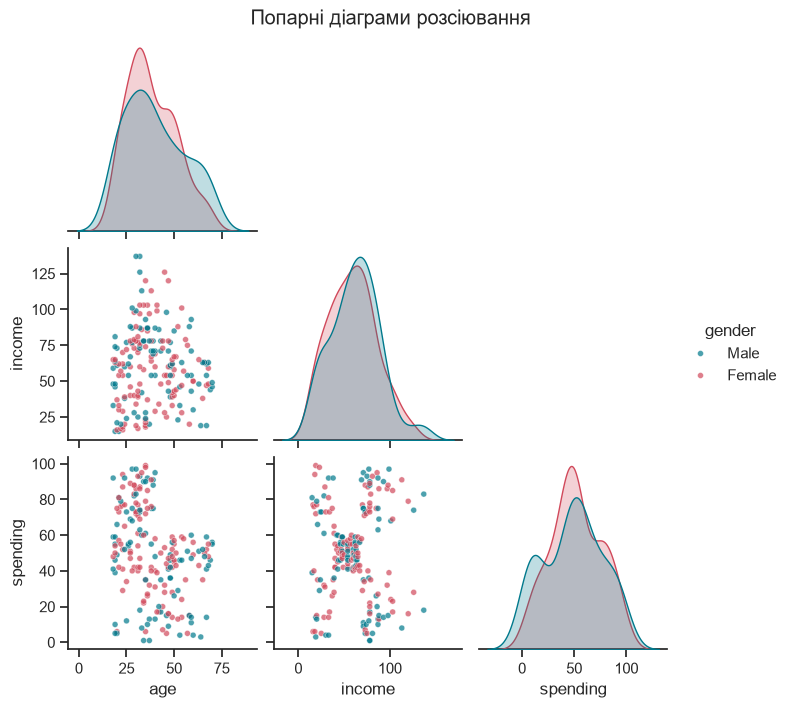

In [12]:
g = sns.pairplot(df, vars=NUM, hue="gender", palette=GENDER_COLORS, corner=True,
                 plot_kws={"s": 18, "alpha": 0.7}, diag_kws={"common_norm": False}, height=2.3)
g.figure.suptitle("Попарні діаграми розсіювання", y=1.02)
g.figure.savefig(FIG / "05_pairplot.png")
plt.show()

### 3.4 Чи є в даних кластерна структура? Статистика Гопкінса

H = Σu / (Σu + Σw), де w — відстані від випадкових точок вибірки до найближчого сусіда у вибірці,
u — відстані від рівномірно згенерованих точок (у межах ознак) до найближчої точки вибірки.
H ≈ 0,5 — дані схожі на випадкові, H → 1 — виражена кластерна структура.

In [13]:
def hopkins(data, rng, frac=0.1):
    n, d = data.shape
    m = max(1, int(frac * n))
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    sample = data[rng.choice(n, m, replace=False)]
    w = nn.kneighbors(sample, n_neighbors=2)[0][:, 1]
    synthetic = rng.uniform(data.min(axis=0), data.max(axis=0), size=(m, d))
    u = nn.kneighbors(synthetic, n_neighbors=1)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())


rng = np.random.default_rng(SEED)
uniform_ref = rng.uniform(size=X["F2"].shape)
hop = {}
for name, data in [("F2", X["F2"]), ("F3", X["F3"]), ("uniform", uniform_ref)]:
    values = [hopkins(data, rng) for _ in range(200)]
    hop[name] = {"mean": float(np.mean(values)), "std": float(np.std(values))}
summary["hopkins"] = hop
pd.DataFrame(hop).T.round(3)

,mean,std
F2,0.706,0.051
F3,0.695,0.037
uniform,0.494,0.041


## 4. K-means

### 4.1 Власна реалізація (k-means++ + алгоритм Ллойда) і звірка зі scikit-learn

Алгоритм мінімізує inertia (WCSS) = Σ‖xᵢ − μ_c(i)‖². Кожна ітерація: (1) призначити точку найближчому центроїду,
(2) перерахувати центроїд як середнє своїх точок. Обидва кроки не збільшують WCSS, тому алгоритм збігається
(до локального мінімуму — звідси кілька запусків `n_init`). k-means++ обирає наступний стартовий центр з імовірністю ∝ D(x)².

In [14]:
def kmeans_pp_init(data, k, rng):
    centers = [data[rng.integers(len(data))]]
    for _ in range(1, k):
        d2 = ((data[:, None, :] - np.array(centers)[None]) ** 2).sum(-1).min(axis=1)
        centers.append(data[rng.choice(len(data), p=d2 / d2.sum())])
    return np.array(centers)


def kmeans_numpy(data, k, n_init=10, max_iter=300, tol=1e-8, seed=SEED):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        centers = kmeans_pp_init(data, k, rng)
        for it in range(1, max_iter + 1):
            labels = ((data[:, None, :] - centers[None]) ** 2).sum(-1).argmin(axis=1)
            new = np.array([data[labels == j].mean(axis=0) if np.any(labels == j) else centers[j]
                            for j in range(k)])
            shift = ((new - centers) ** 2).sum()
            centers = new
            if shift < tol:
                break
        dist = ((data[:, None, :] - centers[None]) ** 2).sum(-1)
        labels, inertia = dist.argmin(axis=1), dist.min(axis=1).sum()
        if best is None or inertia < best["inertia"]:
            best = {"labels": labels, "centers": centers, "inertia": inertia, "n_iter": it}
    return best


own = kmeans_numpy(X["F2"], 5)
ref = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X["F2"])
cost = ((own["centers"][:, None, :] - ref.cluster_centers_[None]) ** 2).sum(-1)
r, c = linear_sum_assignment(cost)
own_check = {"own_inertia": float(own["inertia"]), "sklearn_inertia": float(ref.inertia_),
             "ari": float(adjusted_rand_score(own["labels"], ref.labels_)),
             "max_center_diff": float(np.sqrt(cost[r, c]).max()), "own_n_iter": int(own["n_iter"])}
summary["own_kmeans"] = own_check
own_check

{'own_inertia': 65.56840815571681,
 'sklearn_inertia': 65.56840815571681,
 'ari': 1.0,
 'max_center_diff': 3.3306690738754696e-16,
 'own_n_iter': 10}

### 4.2 Вибір набору ознак і кількості кластерів

Порівнюються два набори ознак: **F2** = {дохід, Spending Score} та **F3** = {вік, дохід, Spending Score}.
Для k = 2…10 рахуються чотири критерії:

* **Elbow (inertia)** — точка «ліктя» знаходиться автоматично методом Kneedle: криву нормалізують до [0, 1],
  лікоть — точка з найбільшою відстанню до хорди між першою та останньою точками;
* **Silhouette** — max; **Calinski–Harabasz** (відношення міжкластерної до внутрішньокластерної дисперсії) — max;
  **Davies–Bouldin** (середня «схожість» кластера з найближчим сусідом) — min.

In [15]:
K = list(range(2, 11))


def scan(data):
    rows = []
    for k in K:
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(data)
        rows.append({"k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(data, km.labels_),
                     "calinski_harabasz": calinski_harabasz_score(data, km.labels_),
                     "davies_bouldin": davies_bouldin_score(data, km.labels_)})
    return pd.DataFrame(rows)


def kneedle(ks, values):
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.array(values) - min(values)) / (max(values) - min(values))
    return int(ks[int(np.argmax((1 - x) - y))])


scans = {name: scan(X[name]) for name in FEATURE_SETS}
votes = {}
for name, s in scans.items():
    votes[name] = {"elbow": kneedle(K, s["inertia"].tolist()),
                   "silhouette": int(s.loc[s["silhouette"].idxmax(), "k"]),
                   "calinski_harabasz": int(s.loc[s["calinski_harabasz"].idxmax(), "k"]),
                   "davies_bouldin": int(s.loc[s["davies_bouldin"].idxmin(), "k"])}
summary["scans"] = {name: s.round(4).to_dict("records") for name, s in scans.items()}
summary["votes"] = votes
display(pd.DataFrame(votes))
for name, s in scans.items():
    print(name)
    display(s.set_index("k").T.round(3))

,F2,F3
elbow,5,4
silhouette,5,6
calinski_harabasz,9,6
davies_bouldin,5,7


F2


k,2,3,4,5,6,7,8,9,10
inertia,269.691,157.704,108.921,65.568,55.057,44.865,37.148,32.392,29.686
silhouette,0.321,0.467,0.494,0.555,0.540,0.528,0.457,0.457,0.436
calinski_harabasz,95.669,151.335,174.595,248.649,243.088,254.621,267.914,270.948,263.350
davies_bouldin,1.267,0.716,0.710,0.572,0.655,0.715,0.758,0.763,0.765


F3


k,2,3,4,5,6,7,8,9,10
inertia,389.386,295.212,205.225,168.248,133.868,117.012,103.829,92.349,81.987
silhouette,0.335,0.358,0.404,0.417,0.427,0.417,0.409,0.420,0.397
calinski_harabasz,107.096,101.695,125.676,125.101,135.102,132.774,131.074,131.242,133.385
davies_bouldin,1.261,1.050,0.931,0.875,0.828,0.793,0.889,0.854,0.906


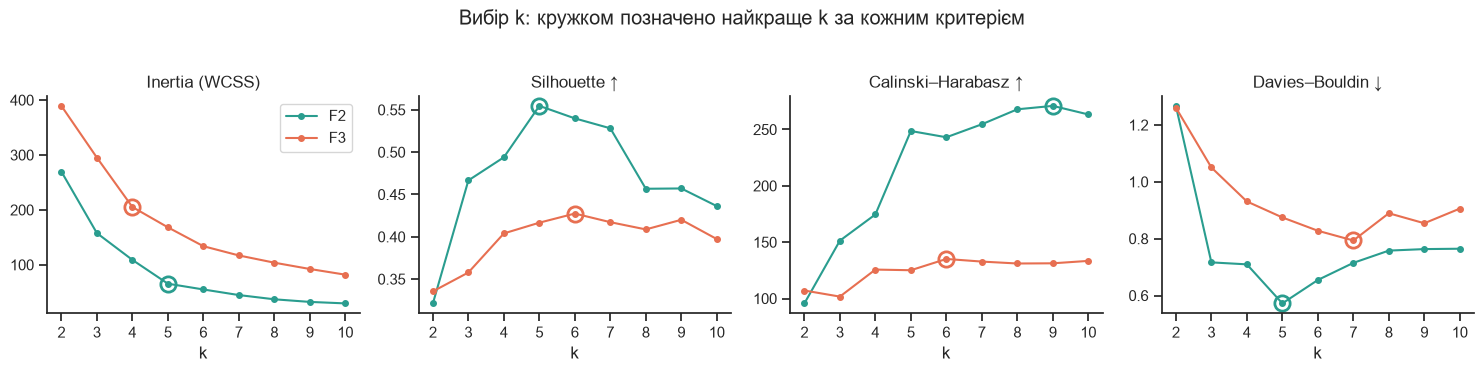

In [16]:
metric_titles = {"inertia": "Inertia (WCSS)", "silhouette": "Silhouette ↑",
                 "calinski_harabasz": "Calinski–Harabasz ↑", "davies_bouldin": "Davies–Bouldin ↓"}
vote_key = {"inertia": "elbow", "silhouette": "silhouette",
            "calinski_harabasz": "calinski_harabasz", "davies_bouldin": "davies_bouldin"}
colors = {"F2": "#2a9d8f", "F3": "#e76f51"}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, metric in zip(axes, metric_titles):
    for name, s in scans.items():
        ax.plot(s["k"], s[metric], "o-", color=colors[name], ms=4, label=name)
        best_k = votes[name][vote_key[metric]]
        ax.plot(best_k, s.set_index("k").loc[best_k, metric], "o", ms=11, mfc="none",
                mec=colors[name], mew=2)
    ax.set_title(metric_titles[metric])
    ax.set_xlabel("k")
    ax.set_xticks(K)
axes[0].legend()
fig.suptitle("Вибір k: кружком позначено найкраще k за кожним критерієм", y=1.03)
fig.tight_layout()
save(fig, "06_k_selection")

Для **F2** три критерії з чотирьох (лікоть, silhouette, Davies–Bouldin) вказують на **k = 5**;
Calinski–Harabasz продовжує повільно зростати до k = 9 (він схильний до більших k), але при k = 5 має чіткий локальний максимум.
Для **F3** критерії розходяться (4, 6, 6, 7), лікоть нечіткий, найкращий silhouette — при k = 6.
Тому основна модель — **F2, k = 5**, а вік використовується для опису сегментів і в додатковому експерименті (розд. 4.5).

### 4.3 Ініціалізація: k-means++ проти випадкової (100 запусків з n_init = 1)

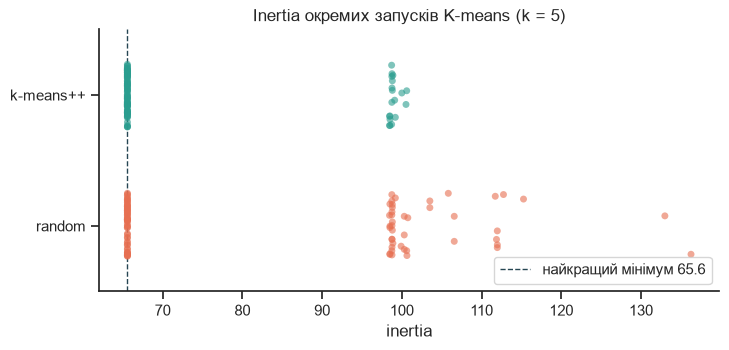

,mean_inertia,worst_inertia,share_global,mean_iter
init,,,,
k-means++,71.921,100.608,0.59,4.75
random,81.951,136.274,0.32,7.09


In [17]:
rows = []
for init in ["k-means++", "random"]:
    for s in range(100):
        km = KMeans(n_clusters=5, init=init, n_init=1, random_state=s).fit(X["F2"])
        rows.append({"init": init, "seed": s, "inertia": km.inertia_, "n_iter": km.n_iter_})
init_df = pd.DataFrame(rows)
best_inertia = init_df["inertia"].min()
init_summary = init_df.groupby("init").agg(
    mean_inertia=("inertia", "mean"), worst_inertia=("inertia", "max"),
    share_global=("inertia", lambda s: float(np.isclose(s, best_inertia, rtol=1e-6).mean())),
    mean_iter=("n_iter", "mean"))
summary["init"] = {"best_inertia": float(best_inertia), **init_summary.round(4).to_dict("index")}

fig, ax = plt.subplots(figsize=(8, 3.4))
sns.stripplot(init_df, x="inertia", y="init", hue="init", palette=["#2a9d8f", "#e76f51"],
              jitter=0.25, alpha=0.6, size=5, ax=ax, legend=False)
ax.axvline(best_inertia, color="#264653", ls="--", lw=1, label=f"найкращий мінімум {best_inertia:.1f}")
ax.legend(loc="lower right")
ax.set_ylabel("")
ax.set_title("Inertia окремих запусків K-means (k = 5)")
save(fig, "07_init")
init_summary.round(3)

### 4.4 Фінальна модель і профілі сегментів

In [18]:
final = KMeans(n_clusters=5, n_init=50, random_state=SEED).fit(X["F2"])
centers = scalers["F2"].inverse_transform(final.cluster_centers_)


def level(v, low, high):
    return "low" if v < low else "high" if v > high else "mid"


SEGMENTS = {("high", "high"): "Преміум-покупці", ("high", "low"): "Стримані заможні",
            ("mid", "mid"): "Масовий сегмент", ("low", "high"): "Активні з малим доходом",
            ("low", "low"): "Ощадливі"}
ORDER = list(SEGMENTS)
keys = [(level(inc, 40, 70), level(sp, 35, 65)) for inc, sp in centers]
assert sorted(keys) == sorted(ORDER)
remap = {old: ORDER.index(key) for old, key in enumerate(keys)}
df["cluster"] = pd.Series(final.labels_).map(remap).values
NAMES = {i: SEGMENTS[key] for i, key in enumerate(ORDER)}
df["segment"] = df["cluster"].map(NAMES)
centers_df = pd.DataFrame(centers, columns=["income", "spending"]).rename(index=remap).sort_index()
labels = df["cluster"].to_numpy()

sil = silhouette_samples(X["F2"], labels)
df["silhouette"] = sil
profile = df.groupby("cluster").agg(
    n=("id", "size"), income=("income", "mean"), spending=("spending", "mean"),
    age=("age", "mean"), age_std=("age", "std"), age_min=("age", "min"), age_max=("age", "max"),
    female_share=("is_female", "mean"), silhouette=("silhouette", "mean"))
profile.insert(0, "segment", profile.index.map(NAMES))
profile.insert(2, "share", profile["n"] / len(df))
summary["profile"] = profile.round(3).reset_index().to_dict("records")
summary["centers"] = centers_df.round(2).reset_index().rename(columns={"index": "cluster"}).to_dict("records")
profile.round(2)

,segment,n,share,income,spending,age,age_std,age_min,age_max,female_share,silhouette
cluster,,,,,,,,,,,
0,Преміум-покупці,39,0.20,86.54,82.13,32.69,3.73,27,40,0.54,0.51
1,Стримані заможні,35,0.18,88.20,17.11,41.11,11.34,19,59,0.46,0.51
2,Масовий сегмент,81,0.40,55.30,49.52,42.72,16.45,18,70,0.59,0.60
3,Активні з малим доходом,22,0.11,25.73,79.36,25.27,5.26,18,35,0.59,0.60
4,Ощадливі,23,0.12,26.30,20.91,45.22,13.23,19,67,0.61,0.51


### 4.5 Додатковий експеримент: що дає вік (F3, k = 6) і навіщо масштабування

Таблиця спряженості показує, як модель на трьох ознаках перерозподіляє клієнтів сегментів F2.
Окремо перевіряється, наскільки змінюється розбиття без стандартизації (ARI з масштабованим варіантом).

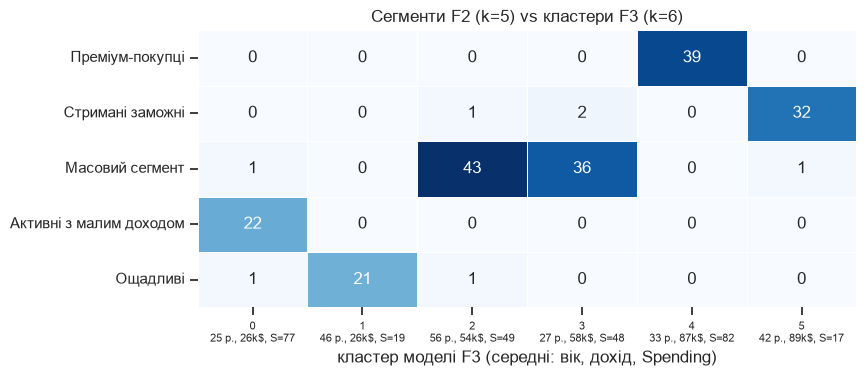

,n,age,income,spending
cluster_f3,,,,
0,24,25.2,25.8,76.9
1,21,45.5,26.3,19.4
2,45,56.3,54.3,49.1
3,38,26.7,57.6,47.8
4,39,32.7,86.5,82.1
5,33,41.9,88.9,17.0


{'F2': 1.0, 'F3': 0.9450619786972076}

In [19]:
f3 = KMeans(n_clusters=6, n_init=50, random_state=SEED).fit(X["F3"])
f3_centers = pd.DataFrame(scalers["F3"].inverse_transform(f3.cluster_centers_), columns=FEATURE_SETS["F3"])
f3_order = f3_centers.sort_values(["income", "spending", "age"]).index.tolist()
f3_labels = pd.Series(f3.labels_).map({old: new for new, old in enumerate(f3_order)}).to_numpy()
df["cluster_f3"] = f3_labels
f3_profile = df.groupby("cluster_f3").agg(n=("id", "size"), age=("age", "mean"),
                                          income=("income", "mean"), spending=("spending", "mean"))
cross = pd.crosstab(df["segment"], df["cluster_f3"]).reindex([NAMES[i] for i in range(5)])

unscaled = {}
for name, k in [("F2", 5), ("F3", 6)]:
    scaled_labels = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(X[name])
    raw_labels = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(df[FEATURE_SETS[name]].to_numpy(float))
    unscaled[name] = float(adjusted_rand_score(scaled_labels, raw_labels))

summary["f3"] = {"silhouette": float(silhouette_score(X["F3"], f3_labels)),
                 "ari_vs_f2": float(adjusted_rand_score(labels, f3_labels)),
                 "profile": f3_profile.round(2).reset_index().to_dict("records"),
                 "cross": {seg: {int(k): int(v) for k, v in row.items()} for seg, row in cross.iterrows()}}
summary["ari_unscaled_vs_scaled"] = unscaled

fig, ax = plt.subplots(figsize=(8.5, 3.6))
col_labels = [f"{i}\n{r.age:.0f} р., {r.income:.0f}k$, S={r.spending:.0f}" for i, r in f3_profile.iterrows()]
sns.heatmap(cross, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, linewidths=0.5,
            xticklabels=col_labels)
ax.set_xlabel("кластер моделі F3 (середні: вік, дохід, Spending)")
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=8, rotation=0)
ax.set_title("Сегменти F2 (k=5) vs кластери F3 (k=6)")
save(fig, "08_f3_crosstab")
display(f3_profile.round(1))
unscaled

## 5. Оцінка якості кластеризації

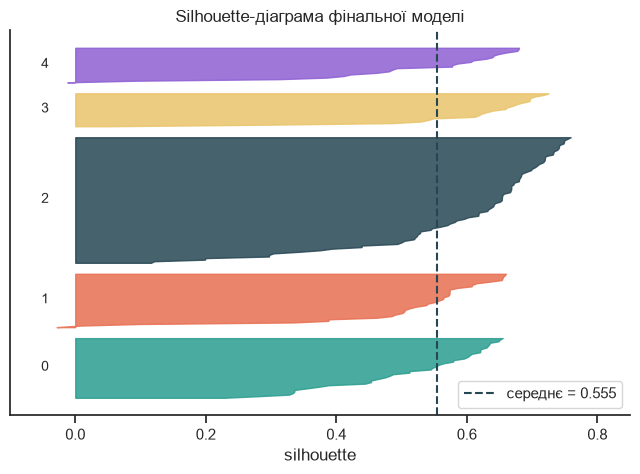

{'silhouette': 0.5546571631111091,
 'davies_bouldin': 0.5722356162263352,
 'calinski_harabasz': 248.64932001536357,
 'inertia': 65.56840815571681,
 'negative_silhouette': 2,
 'low_silhouette': 11}

In [20]:
quality = {"silhouette": float(silhouette_score(X["F2"], labels)),
           "davies_bouldin": float(davies_bouldin_score(X["F2"], labels)),
           "calinski_harabasz": float(calinski_harabasz_score(X["F2"], labels)),
           "inertia": float(final.inertia_),
           "negative_silhouette": int((sil < 0).sum()),
           "low_silhouette": int((sil < 0.25).sum())}
summary["quality"] = quality

fig, ax = plt.subplots(figsize=(8, 5))
y = 0
for i in range(5):
    vals = np.sort(sil[labels == i])
    ax.fill_betweenx(np.arange(y, y + len(vals)), 0, vals, color=PALETTE[i], alpha=0.85)
    ax.text(-0.04, y + len(vals) / 2, f"{i}", va="center", ha="right", fontsize=10)
    y += len(vals) + 6
ax.axvline(quality["silhouette"], color="#264653", ls="--", label=f"середнє = {quality['silhouette']:.3f}")
ax.set_xlim(-0.1, 0.85)
ax.set_yticks([])
ax.set_xlabel("silhouette")
ax.set_title("Silhouette-діаграма фінальної моделі")
ax.legend(loc="lower right")
save(fig, "09_silhouette")
quality

### 5.1 Стабільність: bootstrap

200 разів формується bootstrap-вибірка (з поверненням), на ній навчається K-means, і отримана модель
розмічає всі 200 клієнтів. Порівнюємо з еталонним розбиттям: ARI для всього розбиття і
Jaccard для кожного кластера (максимум по кластерах нової моделі). Jaccard > 0,85 — кластер дуже стабільний.

In [21]:
rng = np.random.default_rng(SEED)
n = len(df)
aris, jaccards = [], []
for b in range(200):
    idx = rng.choice(n, n, replace=True)
    pred = KMeans(n_clusters=5, n_init=10, random_state=b).fit(X["F2"][idx]).predict(X["F2"])
    aris.append(adjusted_rand_score(labels, pred))
    row = []
    for j in range(5):
        a = labels == j
        row.append(max(np.sum(a & (pred == c)) / np.sum(a | (pred == c)) for c in range(5)))
    jaccards.append(row)
jaccards = np.array(jaccards)
stability = {"ari_mean": float(np.mean(aris)), "ari_std": float(np.std(aris)), "ari_min": float(np.min(aris)),
             "jaccard_mean": {NAMES[j]: float(jaccards[:, j].mean()) for j in range(5)},
             "jaccard_p05": {NAMES[j]: float(np.quantile(jaccards[:, j], 0.05)) for j in range(5)}}
summary["stability"] = stability
stability

{'ari_mean': 0.9710589441248255,
 'ari_std': 0.02389498165772426,
 'ari_min': 0.8703755501827419,
 'jaccard_mean': {'Преміум-покупці': 0.9998717948717949,
  'Стримані заможні': 0.97145485334959,
  'Масовий сегмент': 0.9753877943206102,
  'Активні з малим доходом': 0.9808703947992167,
  'Ощадливі': 0.9770665551839466},
 'jaccard_p05': {'Преміум-покупці': 1.0,
  'Стримані заможні': 0.9210526315789473,
  'Масовий сегмент': 0.9397590361445783,
  'Активні з малим доходом': 0.9545454545454546,
  'Ощадливі': 0.9130434782608695}}

### 5.2 Порівняння з іншими алгоритмами: ієрархічна кластеризація (Ward) і DBSCAN

Для DBSCAN параметр eps підбирається за графіком k-distance (відстань до 5-го сусіда) і перебором сітки;
обирається конфігурація з найбільшим silhouette (без точок-шуму) серед тих, де шум < 10%.

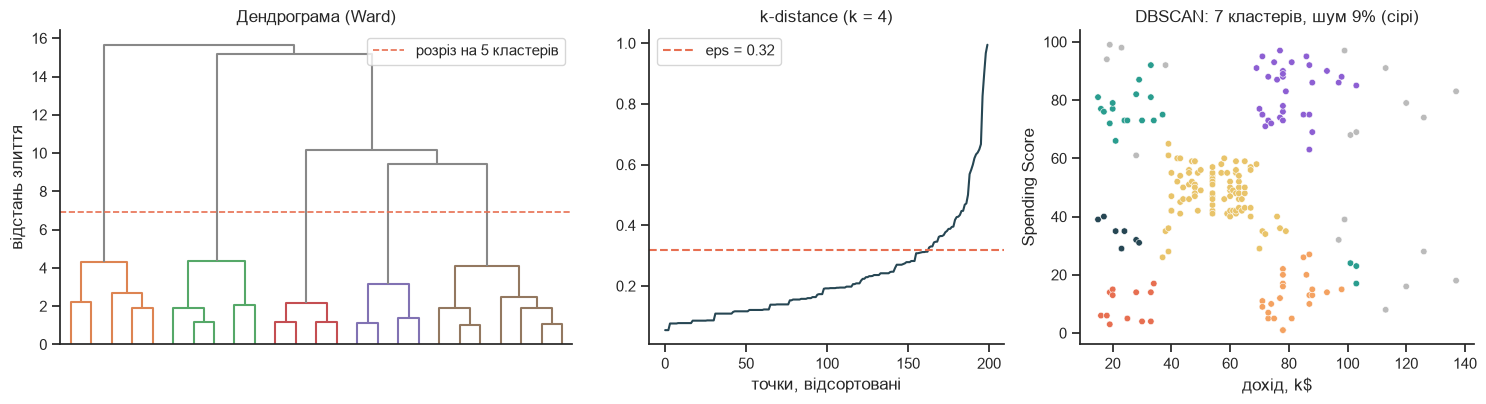

,silhouette,ari,clusters,noise,eps,min_samples
K-means,0.554657,1.000000,5.0,0.00,NaN,NaN
Agglomerative (Ward),0.553809,0.941961,5.0,0.00,NaN,NaN
DBSCAN,0.513507,0.852764,7.0,0.09,0.32,4.0


In [22]:
agg = AgglomerativeClustering(n_clusters=5, linkage="ward").fit(X["F2"])
Z = linkage(X["F2"], method="ward")

grid = []
for eps in np.round(np.arange(0.20, 0.62, 0.02), 2):
    for ms in [4, 5, 6, 8]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X["F2"])
        core = lab != -1
        k_found = len(set(lab[core]))
        if k_found < 2:
            continue
        grid.append({"eps": eps, "min_samples": ms, "clusters": k_found, "noise": float((~core).mean()),
                     "silhouette": silhouette_score(X["F2"][core], lab[core]),
                     "ari_vs_kmeans": adjusted_rand_score(labels[core], lab[core])})
grid = pd.DataFrame(grid)
best_db = grid[grid["noise"] < 0.10].sort_values("silhouette", ascending=False).iloc[0]
db_labels = DBSCAN(eps=best_db["eps"], min_samples=int(best_db["min_samples"])).fit_predict(X["F2"])
kdist = np.sort(NearestNeighbors(n_neighbors=int(best_db["min_samples"])).fit(X["F2"]).kneighbors(X["F2"])[0][:, -1])

alternatives = {
    "K-means": {"silhouette": quality["silhouette"], "ari": 1.0, "clusters": 5, "noise": 0.0},
    "Agglomerative (Ward)": {"silhouette": float(silhouette_score(X["F2"], agg.labels_)),
                             "ari": float(adjusted_rand_score(labels, agg.labels_)), "clusters": 5, "noise": 0.0},
    "DBSCAN": {"silhouette": float(best_db["silhouette"]), "ari": float(best_db["ari_vs_kmeans"]),
               "clusters": int(best_db["clusters"]), "noise": float(best_db["noise"]),
               "eps": float(best_db["eps"]), "min_samples": int(best_db["min_samples"])},
}
summary["alternatives"] = alternatives

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.3, 0.9, 1]})
cut = (Z[-5, 2] + Z[-4, 2]) / 2
dendrogram(Z, ax=axes[0], truncate_mode="lastp", p=25, color_threshold=cut, no_labels=True,
           above_threshold_color="#888888")
axes[0].axhline(cut, color="#e76f51", ls="--", lw=1.2, label="розріз на 5 кластерів")
axes[0].set_title("Дендрограма (Ward)")
axes[0].set_ylabel("відстань злиття")
axes[0].legend()
axes[1].plot(kdist, color="#264653")
axes[1].axhline(best_db["eps"], color="#e76f51", ls="--", label=f"eps = {best_db['eps']:.2f}")
axes[1].set_title(f"k-distance (k = {int(best_db['min_samples'])})")
axes[1].set_xlabel("точки, відсортовані")
axes[1].legend()
db_colors = [PALETTE[l % len(PALETTE)] if l >= 0 else "#bbbbbb" for l in db_labels]
axes[2].scatter(df["income"], df["spending"], c=db_colors, s=22, edgecolor="white", lw=0.4)
axes[2].set_title(f"DBSCAN: {int(best_db['clusters'])} кластерів, шум {best_db['noise']:.0%} (сірі)")
axes[2].set_xlabel("дохід, k$")
axes[2].set_ylabel("Spending Score")
fig.tight_layout()
save(fig, "10_alternatives")
pd.DataFrame(alternatives).T

## 6. Візуалізація кластерів

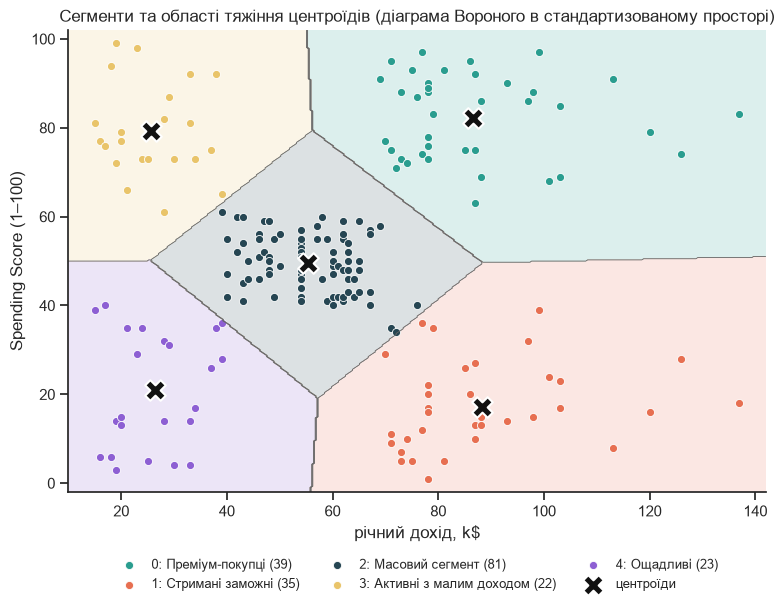

In [23]:
gx, gy = np.meshgrid(np.linspace(10, 142, 400), np.linspace(-2, 102, 400))
grid_pts = scalers["F2"].transform(pd.DataFrame({"income": gx.ravel(), "spending": gy.ravel()}))
region = pd.Series(final.predict(grid_pts)).map(remap).to_numpy().reshape(gx.shape)

fig, ax = plt.subplots(figsize=(9, 6))
ax.contourf(gx, gy, region, levels=np.arange(-0.5, 5.5), cmap=ListedColormap(PALETTE[:5]), alpha=0.16)
ax.contour(gx, gy, region, levels=np.arange(0.5, 4.5), colors="#666666", linewidths=0.6)
for i in range(5):
    part = df[df["cluster"] == i]
    ax.scatter(part["income"], part["spending"], s=34, color=PALETTE[i], edgecolor="white", lw=0.6,
               label=f"{i}: {NAMES[i]} ({len(part)})")
ax.scatter(centers_df["income"], centers_df["spending"], marker="X", s=220, color="#111111",
           edgecolor="white", lw=1.5, label="центроїди")
ax.set_xlabel("річний дохід, k$")
ax.set_ylabel("Spending Score (1–100)")
ax.set_title("Сегменти та області тяжіння центроїдів (діаграма Вороного в стандартизованому просторі)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=9)
save(fig, "11_regions")

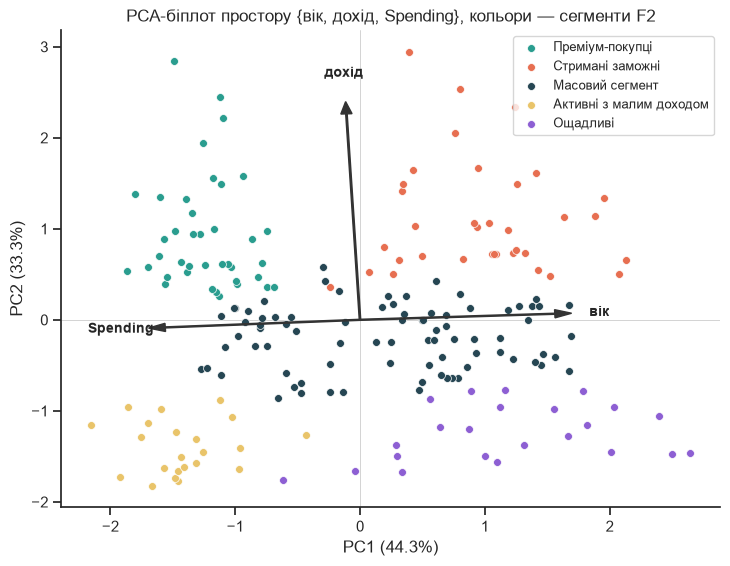

,PC1,PC2,PC3
age,0.706,0.030,0.707
income,-0.048,0.999,0.005
spending,-0.706,-0.038,0.707


In [24]:
pca = PCA(n_components=3).fit(X["F3"])
pcs = pca.transform(X["F3"])
loadings = pd.DataFrame(pca.components_.T, index=FEATURE_SETS["F3"], columns=["PC1", "PC2", "PC3"])
summary["pca"] = {"explained": pca.explained_variance_ratio_.round(4).tolist(),
                  "loadings": loadings.round(3).to_dict()}

fig, ax = plt.subplots(figsize=(8.5, 6.2))
for i in range(5):
    m = labels == i
    ax.scatter(pcs[m, 0], pcs[m, 1], s=32, color=PALETTE[i], edgecolor="white", lw=0.5, label=NAMES[i])
scale = 2.4
for feat, (a, b) in loadings[["PC1", "PC2"]].iterrows():
    ax.arrow(0, 0, a * scale, b * scale, color="#333333", width=0.012, head_width=0.09, length_includes_head=True)
    ax.text(a * scale * 1.13, b * scale * 1.13, {"age": "вік", "income": "дохід", "spending": "Spending"}[feat],
            fontsize=10, ha="center", va="center", fontweight="bold")
ev = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({ev[0]:.1%})")
ax.set_ylabel(f"PC2 ({ev[1]:.1%})")
ax.set_title("PCA-біплот простору {вік, дохід, Spending}, кольори — сегменти F2")
ax.legend(fontsize=9, loc="best")
ax.axhline(0, color="#cccccc", lw=0.6, zorder=0)
ax.axvline(0, color="#cccccc", lw=0.6, zorder=0)
save(fig, "12_pca_biplot")
loadings.round(3)

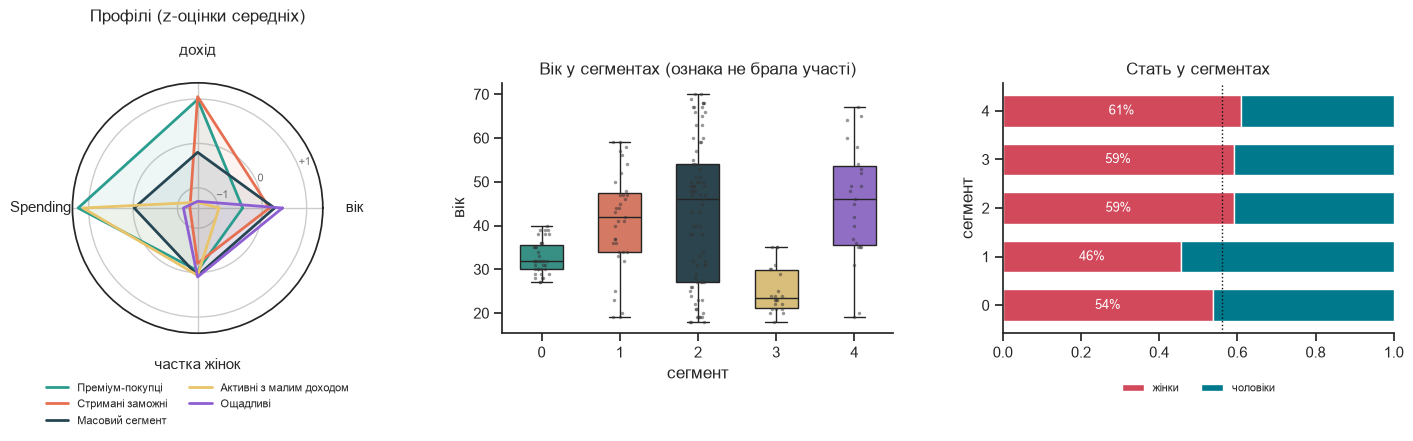

(2.1075190243879856e-08, 0.6931640962057115)

In [25]:
prof_feats = ["age", "income", "spending", "is_female"]
z = df.groupby("cluster")[prof_feats].mean()
z = (z - df[prof_feats].mean()) / df[prof_feats].std()
angles = np.linspace(0, 2 * np.pi, len(prof_feats), endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(15, 4.6))
ax0 = fig.add_subplot(1, 3, 1, polar=True)
for i in range(5):
    vals = z.loc[i].tolist()
    ax0.plot(angles, vals + vals[:1], color=PALETTE[i], lw=2, label=NAMES[i])
    ax0.fill(angles, vals + vals[:1], color=PALETTE[i], alpha=0.08)
ax0.set_xticks(angles[:-1])
ax0.set_xticklabels(["вік", "дохід", "Spending", "частка жінок"])
ax0.tick_params(axis="x", pad=10)
ax0.set_yticks([-1, 0, 1])
ax0.set_yticklabels(["−1", "0", "+1"], fontsize=8, color="#777777")
ax0.set_rlabel_position(22)
ax0.set_title("Профілі (z-оцінки середніх)", pad=16)
ax0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=8, ncol=2, frameon=False)

ax1 = fig.add_subplot(1, 3, 2)
sns.boxplot(df, x="cluster", y="age", hue="cluster", palette=PALETTE[:5], ax=ax1, legend=False, width=0.55)
sns.stripplot(df, x="cluster", y="age", color="#333333", size=2.5, alpha=0.5, ax=ax1)
ax1.set_title("Вік у сегментах (ознака не брала участі)")
ax1.set_xlabel("сегмент")
ax1.set_ylabel("вік")

ax2 = fig.add_subplot(1, 3, 3)
gshare = pd.crosstab(df["cluster"], df["gender"], normalize="index")[["Female", "Male"]]
gshare.plot(kind="barh", stacked=True, color=[GENDER_COLORS["Female"], GENDER_COLORS["Male"]], ax=ax2,
            width=0.65, legend=False)
ax2.legend(ax2.containers, ["жінки", "чоловіки"], loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2,
           fontsize=8, frameon=False)
for i, v in enumerate(gshare["Female"]):
    ax2.text(v / 2, i, f"{v:.0%}", va="center", ha="center", color="white", fontsize=9)
ax2.axvline(df["is_female"].mean(), color="#111111", ls=":", lw=1)
ax2.set_xlim(0, 1)
ax2.set_title("Стать у сегментах")
ax2.set_ylabel("сегмент")
ax2.set_xlabel("")
fig.tight_layout()
save(fig, "13_profiles")
summary["age_kruskal_p"] = float(stats.kruskal(*[df.loc[df.cluster == i, "age"] for i in range(5)]).pvalue)
summary["gender_chi2_p"] = float(stats.chi2_contingency(pd.crosstab(df["cluster"], df["gender"]))[1])
summary["age_kruskal_p"], summary["gender_chi2_p"]

## 7. Збереження результатів

In [26]:
df.drop(columns=["age_group"]).to_csv(RES / "customers_with_segments.csv", index=False)
profile.round(3).to_csv(RES / "segment_profile.csv")


def to_builtin(o):
    if hasattr(o, "item"):
        return o.item()
    return str(o)


(RES / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=to_builtin),
                                  encoding="utf-8")
print(sorted(summary))

['age_groups', 'age_kruskal_p', 'alternatives', 'ari_unscaled_vs_scaled', 'centers', 'checks', 'corr_pearson', 'corr_spearman', 'describe', 'f3', 'gender_chi2_p', 'gender_counts', 'gender_tests', 'hopkins', 'income_outlier_rows', 'init', 'outliers', 'own_kmeans', 'pca', 'profile', 'quality', 'scans', 'stability', 'votes']
